# Quality of the OAQ Airnet sensors

This notebook examines the 15-minute readings (January to September 2026) of the Airnet low-cost PM2.5 sensors in Bengaluru. [OAQ](https://oaq.notf.in) publishes these readings. The notebook does these checks:

1. Completeness: the quantity of the expected readings that are available.
2. Plausibility: negative, zero, extreme and stuck readings, and readings with spikes.
3. Precision: the agreement between the sensors that OAQ lists at one location, the CSTEP Test Bed.
4. Accuracy: the agreement with the nearest CPCB reference station. The reference data are the official CPCB data.
5. Humidity: does the sensor-to-reference ratio change with the relative humidity?

The targets (`EPA_PM25_TARGETS`) come from the US EPA document *Performance Testing Protocols, Metrics, and Target Values for Fine Particulate Matter Air Sensors* (Duvall et al., 2021, EPA/600/R-20/280). The EPA protocol puts the sensors adjacent to the reference monitor. In this notebook, the nearest CPCB station is up to 3 km away. Thus, the accuracy numbers contain the sensor error and real differences between locations. Read these numbers as an upper bound on the sensor error.

Frequently, the OAQ daily record is the last reading of the day, not the mean of the day (refer to the notebook *OAQ low-cost sensors vs the nearest CPCB station*). Thus, each daily value in this notebook is a mean of 15-minute readings (`readings_mean`). The R package has the same functions. You must have `OAQ_API_KEY` for the OAQ calls.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from vayuayan import (
    EPA_PM25_TARGETS,
    CPCBHistorical,
    OAQClient,
    collocated_precision,
    oaq_nearest_cpcb,
    peer_ratio,
    plot_sensor_vs_reference,
    ratio_by_humidity,
    readings_mean,
    sensor_accuracy,
    sensor_completeness,
    sensor_plausibility,
    set_theme,
)
from vayuayan.plot_theme import AXIS, PALETTE

set_theme()
pd.set_option("display.width", 160)
oaq = OAQClient()
cpcb = CPCBHistorical()
START, END = "2026-01-01", "2026-09-30"
EPA_PM25_TARGETS

{'completeness': 0.75,
 'sd': 5.0,
 'cv_pct': 30.0,
 'slope': (0.65, 1.35),
 'intercept': (-5.0, 5.0),
 'r2': 0.7,
 'rmse': 7.0,
 'nrmse_pct': 30.0}

## The sensors and their readings

In [2]:
sensors = oaq.sensors(["airnet"])
sites = sensors.groupby(["lat", "lon"]).agg(
    sensors=("id", "size"), name=("name", "first")
)
print(f"{len(sensors)} Airnet sensors at {len(sites)} places")
sites[sites.sensors > 1]

47 Airnet sensors at 28 places


,,sensors,name
lat,lon,,
12.814517,77.705516,2,Tranquil City
13.035533,77.534676,2,Yeshwantpur Stage 1
13.048451,77.579592,18,CSTEP Test Bed


In [3]:
readings = oaq.readings("airnet", sensors["id"], pd.date_range(START, END))
readings = readings[["sensor_id", "timestamp", "pm25"]]
print(f"{len(readings):,} readings of {readings.sensor_id.nunique()} sensors")

482,558 readings of 47 sensors


## 1. Completeness

This section counts the readings that have a PM2.5 value, out of 96 each day. It also counts the days that have a valid 24-hour average (75 % of the readings).

In [4]:
completeness = sensor_completeness(readings, START, END, ids=sensors["id"])
completeness = completeness.merge(
    sensors[["id", "name"]], left_on="sensor_id", right_on="id"
).drop(columns="id")
print(
    f"Sensors with a valid 24-hour average on at least 75 % of the days: "
    f"{(completeness.valid_days_pct >= 75).sum()} of {len(completeness)}"
)
completeness[["readings_pct", "valid_days_pct"]].describe().round(1)

Sensors with a valid 24-hour average on at least 75 % of the days: 0 of 47


,readings_pct,valid_days_pct
count,47.0,47.0
mean,35.9,23.5
std,25.4,26.2
min,0.0,0.0
25%,11.6,0.4
50%,39.6,13.6
75%,57.8,45.1
max,73.8,72.2


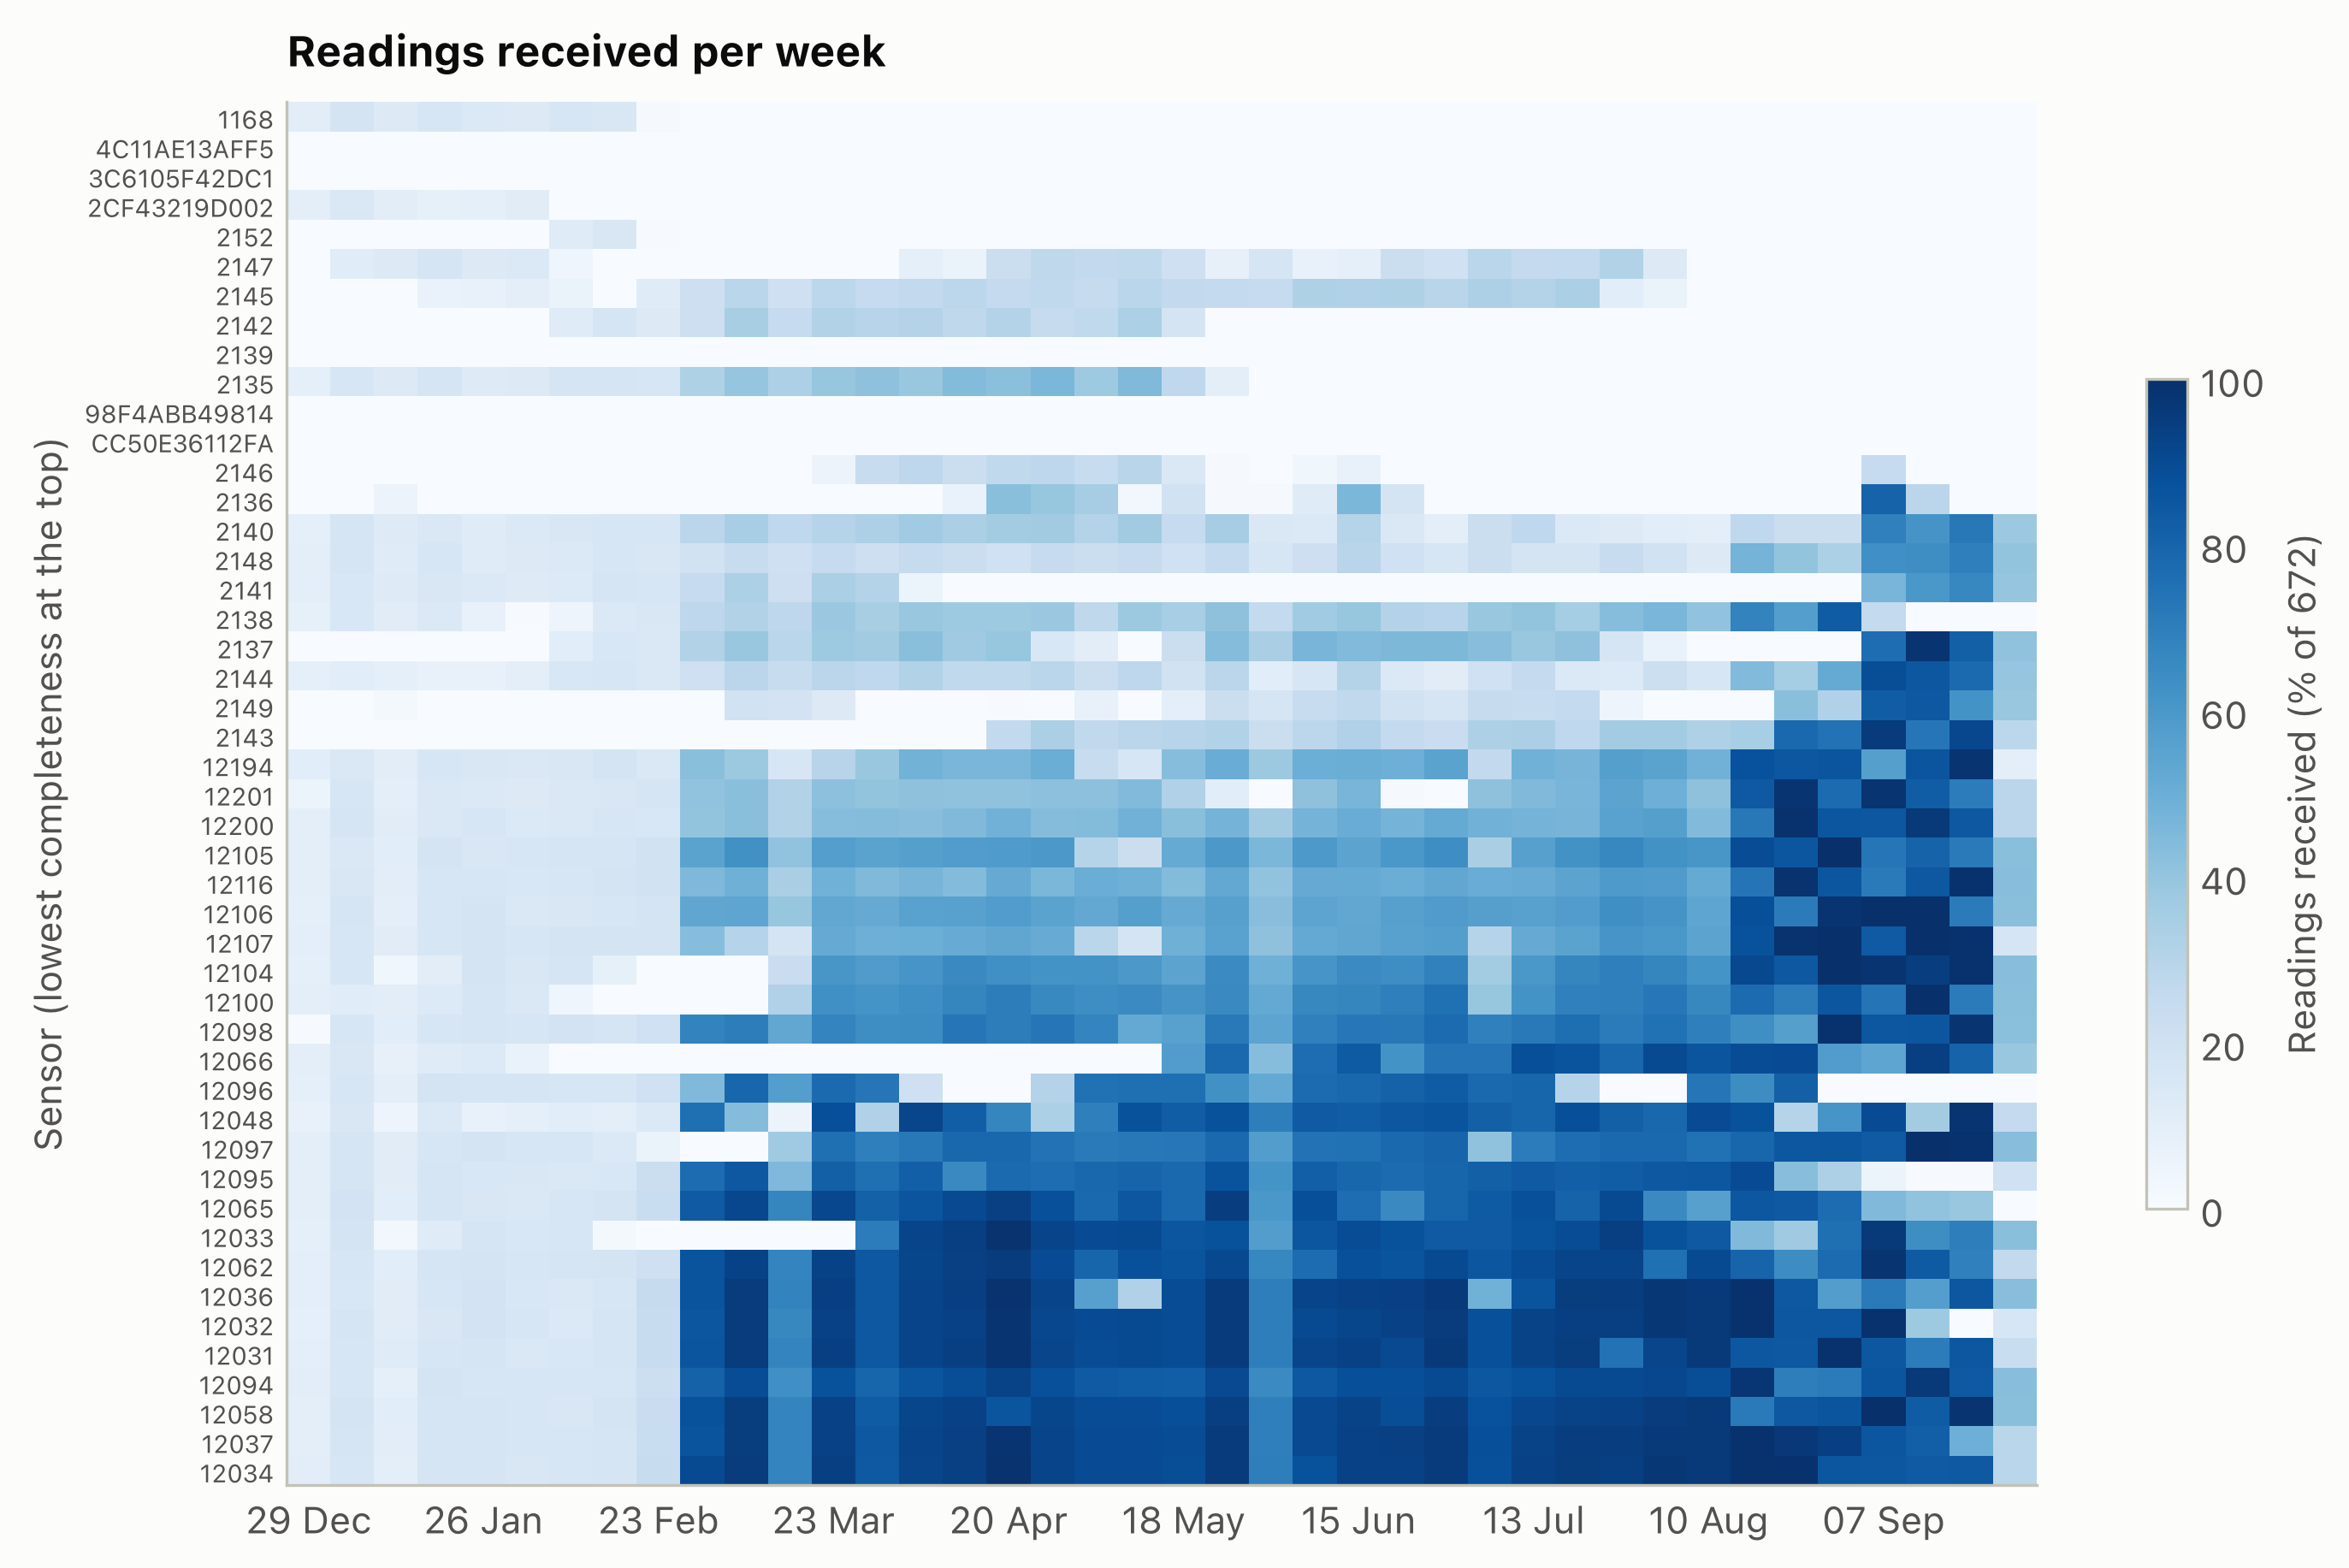

In [5]:
weekly = readings.dropna(subset=["pm25"]).assign(
    week=lambda d: d.timestamp.dt.to_period("W").dt.start_time
)
grid = weekly.pivot_table(
    index="sensor_id", columns="week", values="pm25", aggfunc="size", fill_value=0
)
grid = (
    (100 * grid / (7 * 96))
    .reindex(completeness.sort_values("valid_days_pct").sensor_id)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(
    grid.values, aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest"
)
ax.grid(False)
ax.set_yticks(range(len(grid)), grid.index, fontsize=7)
ax.set_xticks(
    range(0, grid.shape[1], 4), [w.strftime("%d %b") for w in grid.columns[::4]]
)
ax.set_ylabel("Sensor (lowest completeness at the top)")
ax.set_title("Readings received per week")
fig.colorbar(im, ax=ax, shrink=0.6, label="Readings received (% of 672)")
plt.show()

## 2. Plausibility

`sensor_plausibility` identifies these readings:

- negative readings
- readings that are equal to 0
- readings of more than 1000 µg/m³
- readings in a *stuck* run (the same value 8 or more times in sequence, 2 hours)
- *spikes*: readings of more than 10 times the median of the 2 hours around them, and more than 100 µg/m³.

These rules are plausibility rules. They are not EPA targets.

In [6]:
plausibility = sensor_plausibility(readings)
plausibility.describe().round(3)

,readings,negative_pct,zero_pct,above_max_pct,stuck_pct,spikes_pct
count,43.000,43.0,43.0,43.0,43.0,43.000
mean,10295.093,0.0,0.0,0.0,0.0,0.002
std,6259.422,0.0,0.0,0.0,0.0,0.006
min,1.000,0.0,0.0,0.0,0.0,0.000
25%,4214.000,0.0,0.0,0.0,0.0,0.000
50%,11076.000,0.0,0.0,0.0,0.0,0.000
75%,15215.500,0.0,0.0,0.0,0.0,0.000
max,19331.000,0.0,0.0,0.0,0.0,0.026


In [7]:
flags = ["negative_pct", "zero_pct", "above_max_pct", "stuck_pct", "spikes_pct"]
plausibility[(plausibility[flags] > 1).any(axis=1)].round(2)

,sensor_id,readings,negative_pct,zero_pct,above_max_pct,stuck_pct,spikes_pct


## 3. Precision at the CSTEP Test Bed

The CSTEP Test Bed has the largest group of sensors that OAQ lists at the same coordinates. For each day with a valid mean from a minimum of 3 of these sensors, `collocated_precision` gives the SD and the CV across the sensors.

In [8]:
daily = readings_mean(readings)
bed_place = sites.sensors.idxmax()
bed = sensors.set_index(["lat", "lon"]).loc[[bed_place], "id"].tolist()
precision = collocated_precision(daily[daily.sensor_id.isin(bed)])
print(
    f"{sites.loc[bed_place, 'name']}: {len(bed)} sensors, {len(precision)} days with 3 or more valid sensors"
)
pd.DataFrame(
    {
        "median": precision[["sd", "cv_pct"]].median(),
        "days meeting the target (%)": [
            100 * (precision.sd <= EPA_PM25_TARGETS["sd"]).mean(),
            100 * (precision.cv_pct <= EPA_PM25_TARGETS["cv_pct"]).mean(),
        ],
        "EPA target": [EPA_PM25_TARGETS["sd"], EPA_PM25_TARGETS["cv_pct"]],
    }
).round(1)

CSTEP Test Bed: 18 sensors, 65 days with 3 or more valid sensors


,median,days meeting the target (%),EPA target
sd,6.1,24.6,5.0
cv_pct,26.3,70.8,30.0


This section shows the sensors that are different from the other sensors. `peer_ratio` gives the median ratio of each sensor to the median of the other sensors on the same day. It also gives the proportion of days in the range ±30 %.

In [9]:
peers = peer_ratio(daily[daily.sensor_id.isin(bed)])
peers.round(2)

,sensor_id,days,median_ratio,within_pct
0,2149,24,0.63,33.33
1,2143,31,0.65,38.71
2,12107,40,0.89,100.00
3,12036,55,0.91,100.00
4,12104,46,0.93,95.65
5,2137,21,0.99,100.00
6,12100,55,1.06,63.64
7,12105,38,1.07,100.00
8,12194,34,1.09,94.12
9,12097,61,1.44,29.51


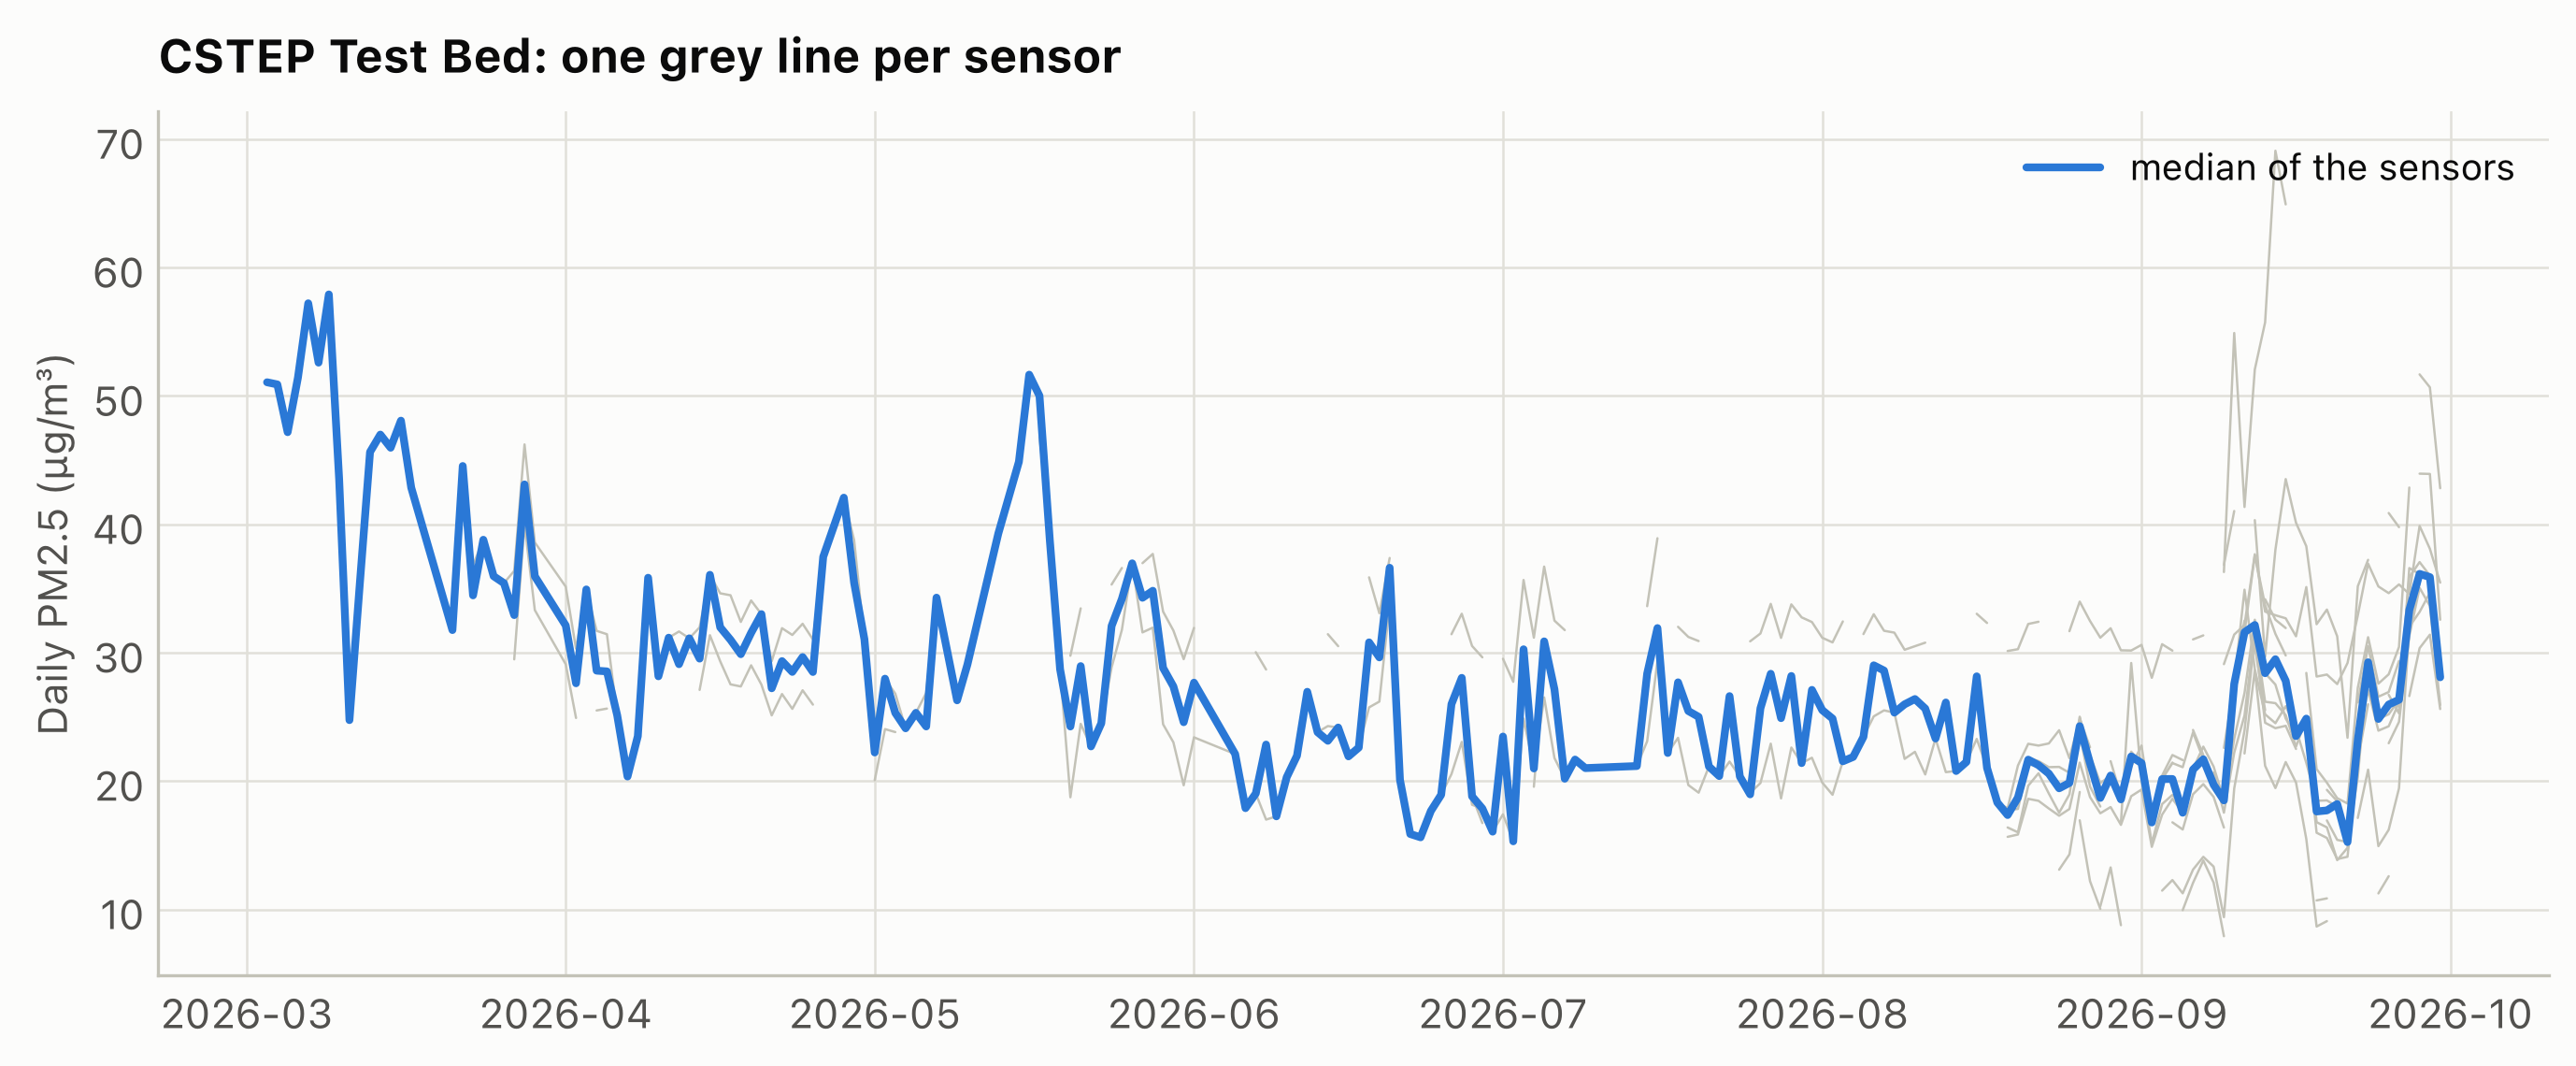

In [10]:
wide = daily[daily.sensor_id.isin(bed)].pivot(
    index="date", columns="sensor_id", values="pm25"
)
wide.index = pd.to_datetime(wide.index)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(wide.index, wide.values, color=AXIS, lw=0.6)
ax.plot(
    wide.index,
    wide.median(axis=1),
    color=PALETTE[0],
    lw=2,
    label="median of the sensors",
)
ax.set_ylabel("Daily PM2.5 (µg/m³)")
ax.set_title("CSTEP Test Bed: one grey line per sensor")
ax.legend(loc="upper right")
plt.show()

## 4. Accuracy against the nearest CPCB station

The reference data are the official CPCB 15-minute data (`CPCBHistorical.raw_readings`). These data come from the nearest CPCB station that is 3 km or less from each sensor. The notebook calculates the averages of these data with the same method. `sensor_accuracy` fits *sensor = intercept + slope × CPCB* for each sensor with a minimum of 30 paired days. It gives R², RMSE and NRMSE. It also gives the EPA targets that each sensor complies with.

In [11]:
pairs = oaq_nearest_cpcb(sensors, k=1).query("distance_km <= 3")
raw = cpcb.raw_readings(
    pairs.cpcb_station_id.unique(), 2026, pollutants=["PM2.5", "RH"]
)
reference = readings_mean(
    raw[raw.pollutant == "PM2.5"], value="value", id_col="station_id"
)
paired = daily.merge(
    pairs[["sensor_id", "cpcb_station_id", "distance_km"]], on="sensor_id"
).merge(
    reference.rename(columns={"station_id": "cpcb_station_id", "value": "reference"}),
    on=["cpcb_station_id", "date"],
)
print(
    f"{len(paired)} sensor-days of {paired.sensor_id.nunique()} sensors; "
    f"CPCB stations with data: {sorted(reference.station_id.unique())}"
)

SSL verification failed for airquality.cpcb.gov.in; sending without verification


770 sensor-days of 15 sensors; CPCB stations with data: ['site_1553', 'site_1554', 'site_162', 'site_164', 'site_5681', 'site_5729']


In [12]:
accuracy = sensor_accuracy(paired)
accuracy = accuracy.merge(
    pairs[["sensor_id", "cpcb_station_name", "distance_km"]], on="sensor_id"
)
accuracy["test bed"] = accuracy.sensor_id.isin(bed)
targets = ["slope_ok", "intercept_ok", "r2_ok", "error_ok"]
print(
    "Sensors meeting each target:",
    accuracy[targets].sum().to_dict(),
    f"of {len(accuracy)}",
)
accuracy.drop(columns=targets).sort_values("r2").round(2)

Sensors meeting each target: {'slope_ok': 7, 'intercept_ok': 1, 'r2_ok': 2, 'error_ok': 1} of 11


,sensor_id,days,slope,intercept,r2,rmse,nrmse_pct,targets_met,cpcb_station_name,distance_km,test bed
5,12097,100,-0.05,32.48,0.02,18.68,92.85,0,"Hebbal, Bengaluru - KSPCB",2.25,True
1,12048,63,0.20,14.76,0.07,23.41,65.75,0,"BWSSB Kadabesanahalli, Bengaluru - CPCB",0.54,False
3,12094,38,-0.59,44.54,0.16,19.18,51.09,0,"Kasturi Nagar, Bengaluru - KSPCB",2.79,False
7,12104,41,0.73,11.82,0.44,9.06,59.84,1,"Hebbal, Bengaluru - KSPCB",2.25,True
2,12065,101,1.32,-12.35,0.48,13.15,41.15,1,"Jigani, Bengaluru - KSPCB",1.85,False
6,12100,45,0.89,15.96,0.49,16.15,99.31,1,"Hebbal, Bengaluru - KSPCB",2.25,True
4,12096,71,0.81,-0.40,0.61,8.57,37.06,2,"Bapuji Nagar, Bengaluru - KSPCB",0.14,False
10,12194,30,1.23,6.81,0.65,10.74,74.23,1,"Hebbal, Bengaluru - KSPCB",2.25,True
9,12107,36,0.90,7.23,0.68,6.43,41.85,2,"Hebbal, Bengaluru - KSPCB",2.25,True
8,12105,33,1.18,7.21,0.74,10.59,68.05,2,"Hebbal, Bengaluru - KSPCB",2.25,True


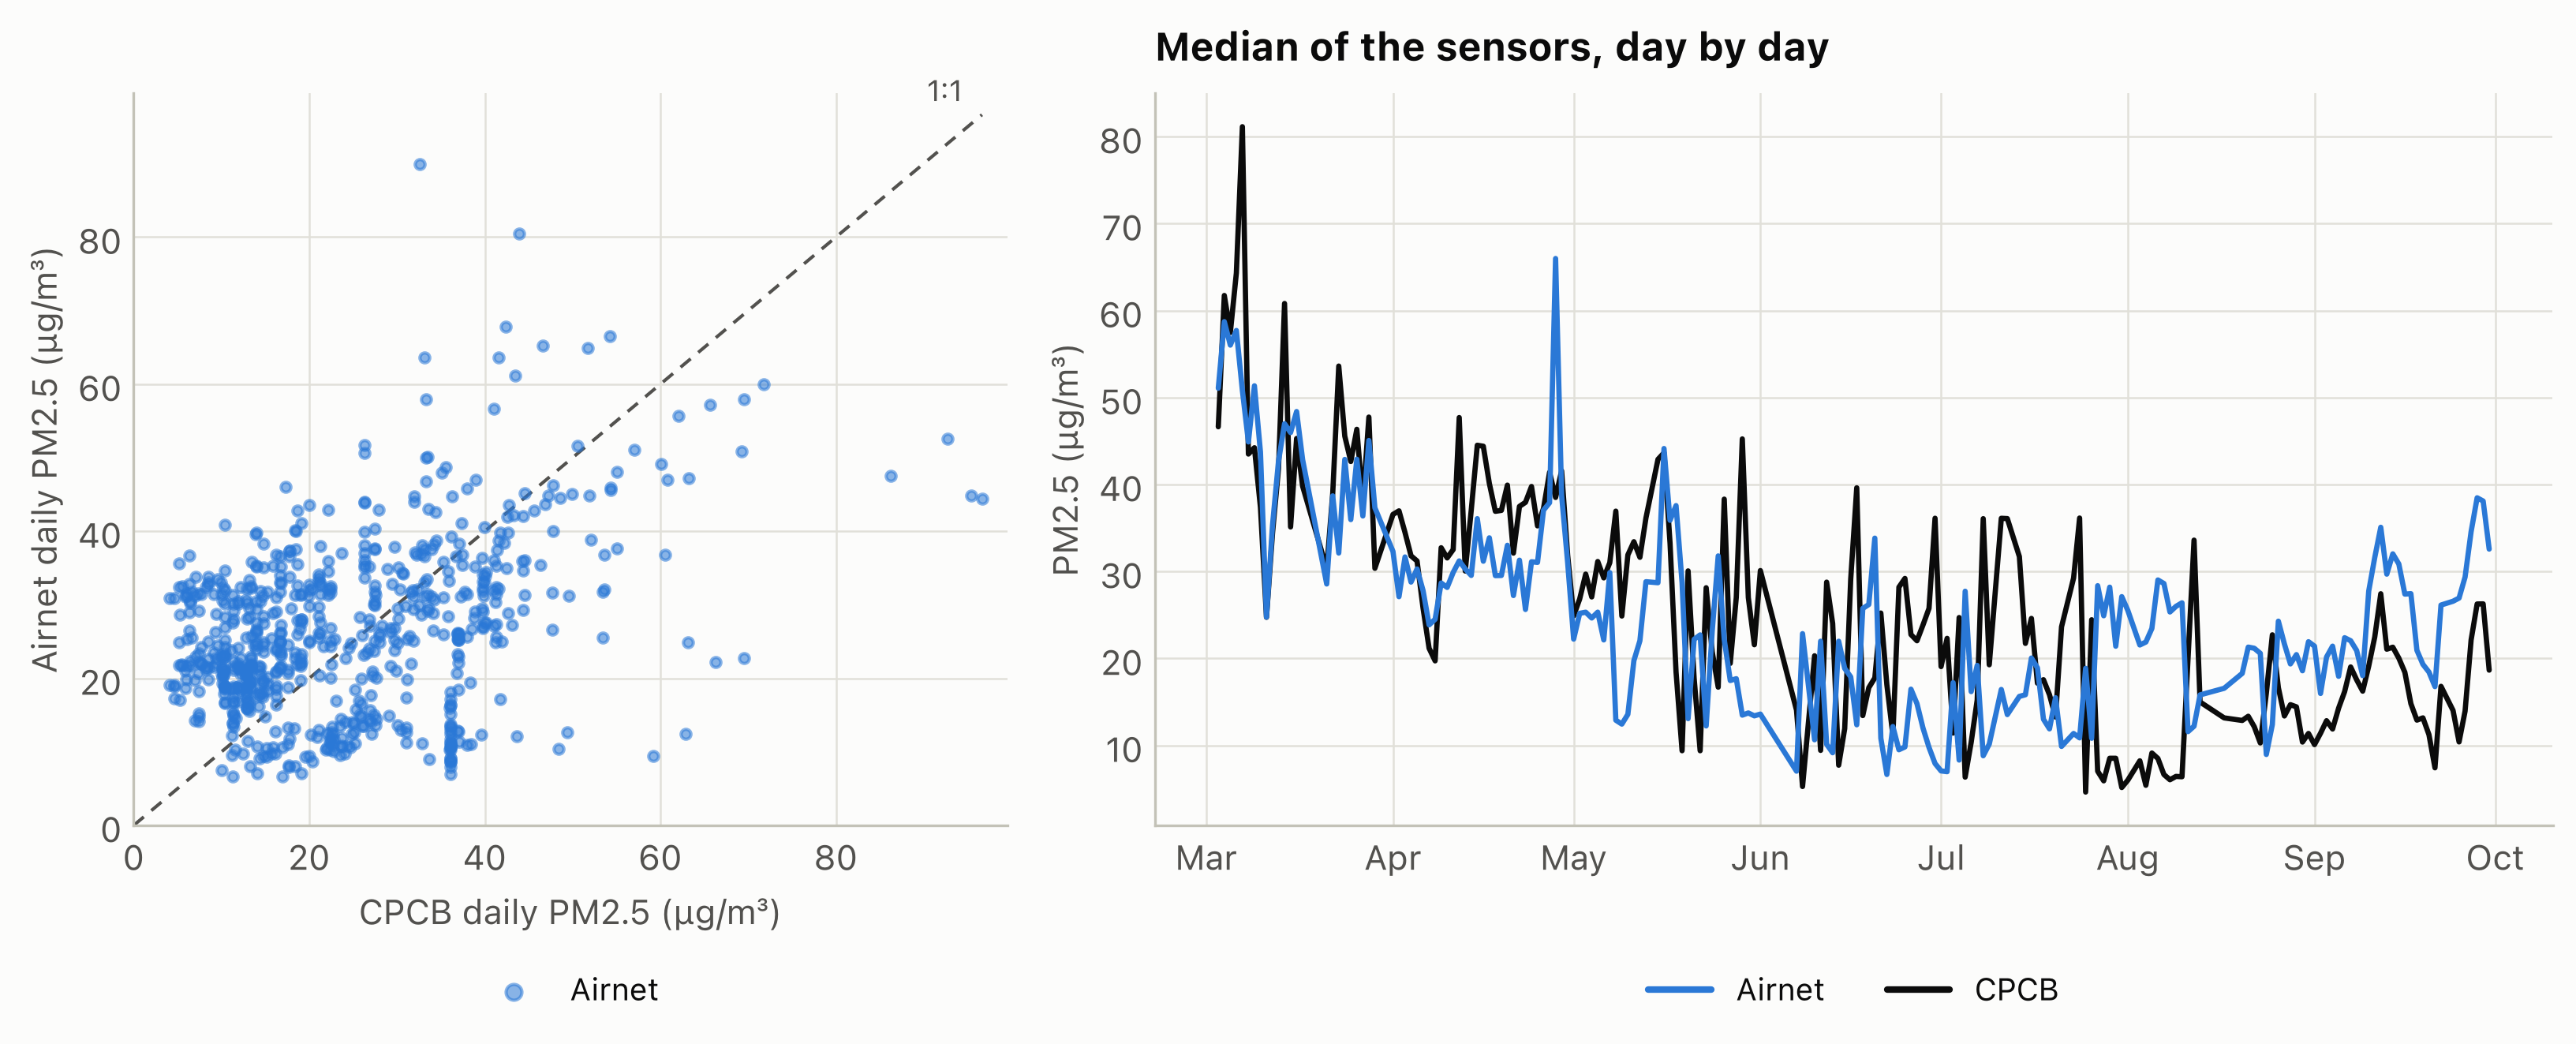

In [13]:
shown = paired[paired.sensor_id.isin(accuracy.sensor_id)]
plot_sensor_vs_reference(shown, sensor_label="Airnet", reference_label="CPCB")

## 5. Relative humidity

Optical sensors can give high readings in humid air, when particles absorb water. `ratio_by_humidity` compares the hourly medians of the test-bed sensors with the CPCB station nearest to the test bed. That station also measures the relative humidity.

In [14]:
station = pairs.loc[pairs.sensor_id.isin(bed), "cpcb_station_id"].mode()[0]
cpcb_hourly = {
    p: readings_mean(
        raw[(raw.station_id == station) & (raw.pollutant == p)],
        value="value",
        by="hour",
        id_col="station_id",
    ).set_index("hour")["value"]
    for p in ["PM2.5", "RH"]
}
hourly = pd.DataFrame(
    {
        "sensor": readings_mean(readings[readings.sensor_id.isin(bed)], by="hour")
        .groupby("hour")
        .pm25.median(),
        "reference": cpcb_hourly["PM2.5"],
        "rh": cpcb_hourly["RH"],
    }
).dropna()
print(f"{len(hourly)} hours at {station}")
ratio_by_humidity(hourly).round(2)

3507 hours at site_1554


,band,hours,median_ratio,q25,q75
0,0-40,58,1.14,1.07,1.26
1,40-50,334,1.46,1.14,2.04
2,50-60,663,1.71,1.22,2.65
3,60-70,1002,1.65,1.02,2.33
4,70-80,513,0.89,0.74,1.41
5,80-90,383,0.84,0.69,1.07
6,90-100,213,0.92,0.76,1.14


## Scorecard

The scorecard has one row for each sensor. When you run the notebook again, the notebook calculates all the numbers again.

In [15]:
score = (
    completeness[["sensor_id", "name", "valid_days_pct"]]
    .merge(
        plausibility.assign(flagged_pct=plausibility[flags].sum(axis=1))[
            ["sensor_id", "flagged_pct"]
        ],
        on="sensor_id",
        how="left",
    )
    .merge(
        peers[["sensor_id", "median_ratio"]].rename(
            columns={"median_ratio": "ratio_to_peers"}
        ),
        on="sensor_id",
        how="left",
    )
    .merge(
        accuracy[["sensor_id", "r2", "slope", "rmse", "targets_met"]],
        on="sensor_id",
        how="left",
    )
)
score.sort_values("valid_days_pct", ascending=False).round(2)

,sensor_id,name,valid_days_pct,flagged_pct,ratio_to_peers,r2,slope,rmse,targets_met
4,12034,Rachenahalli,72.16,0.00,NaN,NaN,NaN,NaN,NaN
6,12037,Attur Layout,71.43,0.03,NaN,NaN,NaN,NaN,NaN
8,12058,Yeshwantpur Stage 1,70.70,0.00,NaN,NaN,NaN,NaN,NaN
12,12094,Mahadevapura,70.33,0.00,NaN,0.16,-0.59,19.18,0.0
1,12031,Rajanukunte,69.60,0.00,NaN,NaN,NaN,NaN,NaN
2,12032,Kumarapark west,68.13,0.00,NaN,NaN,NaN,NaN,NaN
5,12036,CSTEP Test Bed,66.67,0.00,0.91,0.76,0.47,11.15,1.0
9,12062,Shakti Layout,65.93,0.00,NaN,NaN,NaN,NaN,NaN
3,12033,Tranquil City,55.68,0.01,NaN,NaN,NaN,NaN,NaN
10,12065,Jigani Industrial Area-2,53.48,0.01,NaN,0.48,1.32,13.15,1.0


## Notes

- The plausibility rules come from this package. They do not come from the EPA protocol.
- The accuracy check uses a CPCB station up to 3 km away, not a collocated monitor. Thus, the accuracy includes real differences between locations.
- The notebook uses the OAQ coordinates for the location of each sensor. The notebook identifies sensors with the same coordinates as collocated sensors. The OAQ coordinates are the only location data that are available.